## Part 1 - Memorize

In [ ]:
import numpy as np
from data import load_mnist, one_hot
import matplotlib.pyplot as plt
from pathlib import Path

def evaluate(X, Y, W_0_1, W_1_2):
    layer_1 = relu(X @ W_0_1)
    layer_2 = layer_1 @ W_1_2

    predictions = np.argmax(layer_2, axis=1)
    targets = np.argmax(Y, axis=1)

    return np.mean(predictions == targets)

def relu(x):
    return (x > 0) * x


def relu_d(x):
    return x > 0


def train(X_train, Y_train, X_val, Y_val, iterations=350):
    np.random.seed(1)

    alpha = 0.005
    hidden_size = 40

    W_0_1 = 0.2 * np.random.random((784, hidden_size)) - 0.1
    W_1_2 = 0.2 * np.random.random((hidden_size, 10)) - 0.1

    train_hist = []
    val_hist = []

    for j in range(iterations):
        correct = 0
        for i in range(len(X_train)):
            layer_0 = X_train[i:i + 1]
            layer_1 = relu(layer_0 @ W_0_1)
            layer_2 = layer_1 @ W_1_2
            correct += int(np.argmax(layer_2) == np.argmax(Y_train[i]))
            delta_2 = layer_2 - Y_train[i:i + 1]
            delta_1 = (delta_2 @ W_1_2.T) * relu_d(layer_1)
            W_1_2 -= alpha * (layer_1.T @ delta_2)
            W_0_1 -= alpha * (layer_0.T @ delta_1)

        train_hist.append(correct / len(X_train))
        val_hist.append(evaluate(X_val, Y_val, W_0_1, W_1_2))

    return W_0_1, W_1_2, train_hist, val_hist


if __name__ == "__main__":
    (X_train, y_train), (X_test, y_test) = load_mnist()

    X_val = X_train[1000:2000]
    Y_val = one_hot(y_train[1000:2000])

    X_train = X_train[:1000]
    Y_train = one_hot(y_train[:1000])

    print("Training images:", X_train.shape)
    print("Training targets:", Y_train.shape)
    print("Validation images:", X_val.shape)
    print("Validation targets:", Y_val.shape)
    print("Pixel range:", X_train.min(), X_train.max())

    W_0_1, W_1_2, train_hist, val_hist = train(
        X_train, Y_train, X_val, Y_val
    )

    best_pass = np.argmax(val_hist) + 1

    print(f"Final training accuracy: {train_hist[-1]:.1%}")
    print(f"Final validation accuracy: {val_hist[-1]:.1%}")
    print(f"Best validation accuracy: {max(val_hist):.1%}")
    print(f"Best validation pass: {best_pass}")

Training images: (1000, 784)
Training targets: (1000, 10)
Validation images: (1000, 784)
Validation targets: (1000, 10)
Pixel range: 0.0 1.0
Final training accuracy: 99.9%
Final validation accuracy: 82.8%
Best validation accuracy: 87.3%
Best validation pass: 28


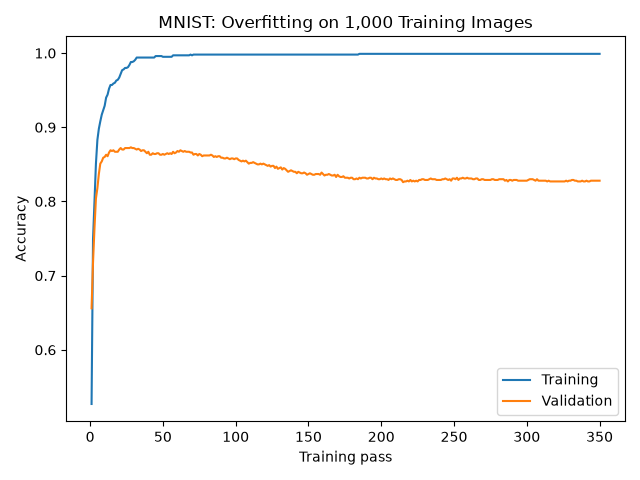

## Part 2 - Early Stopping

In [2]:
#------part2_early_stopping.py--------#
#----------Andrew_Martin--------------#
import copy
import numpy as np
from data import load_mnist, one_hot


def relu(x):
    return (x > 0) * x


def relu_d(x):
    return x > 0


def evaluate(X, Y, W_0_1, W_1_2):
    layer_1 = relu(X @ W_0_1)
    layer_2 = layer_1 @ W_1_2

    predictions = np.argmax(layer_2, axis=1)
    targets = np.argmax(Y, axis=1)

    return np.mean(predictions == targets)


def train_early_stopping(X_train, Y_train, X_val, Y_val, iterations=350, patience=10):
    np.random.seed(1)

    alpha = 0.005
    hidden_size = 40

    W_0_1 = 0.2 * np.random.random((784, hidden_size)) - 0.1
    W_1_2 = 0.2 * np.random.random((hidden_size, 10)) - 0.1

    train_hist = []
    val_hist = []

    best_val_acc = -1.0
    best_weights = (copy.deepcopy(W_0_1), copy.deepcopy(W_1_2))
    wait = 0
    stop_iter = iterations - 1

    for j in range(iterations):
        correct = 0
        for i in range(len(X_train)):
            layer_0 = X_train[i:i + 1]
            layer_1 = relu(layer_0 @ W_0_1)
            layer_2 = layer_1 @ W_1_2
            correct += int(np.argmax(layer_2) == np.argmax(Y_train[i]))
            delta_2 = layer_2 - Y_train[i:i + 1]
            delta_1 = (delta_2 @ W_1_2.T) * relu_d(layer_1)
            W_1_2 -= alpha * (layer_1.T @ delta_2)
            W_0_1 -= alpha * (layer_0.T @ delta_1)

        train_hist.append(correct / len(X_train))
        val_acc = evaluate(X_val, Y_val, W_0_1, W_1_2)
        val_hist.append(val_acc)

        # early stopping: remember the best weights, count passes with no improvement
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_weights = (copy.deepcopy(W_0_1), copy.deepcopy(W_1_2))
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                stop_iter = j
                break

    # outside the loop on purpose: a run that never hits patience still returns the best weights
    W_0_1, W_1_2 = best_weights

    return W_0_1, W_1_2, stop_iter, train_hist, val_hist


if __name__ == "__main__":
    (X_train, y_train), (X_test, y_test) = load_mnist()

    X_val = X_train[1000:2000]
    Y_val = one_hot(y_train[1000:2000])

    X_train = X_train[:1000]
    Y_train = one_hot(y_train[:1000])

    W_0_1, W_1_2, stop_iter, train_hist, val_hist = train_early_stopping(
        X_train, Y_train, X_val, Y_val, iterations=350, patience=10
    )

    best_val_acc = max(val_hist)
    best_pass = np.argmax(val_hist)

    print(f"Stopped at pass {stop_iter} (best pass {best_pass})")
    print(f"Best validation accuracy: {best_val_acc:.1%}")
    print(f"Restored weights score best validation exactly: "
          f"{evaluate(X_val, Y_val, W_0_1, W_1_2) == best_val_acc}")

    # the only test-set number in the whole assignment
    Y_test = one_hot(y_test)
    print(f"Test accuracy (restored weights): {evaluate(X_test, Y_test, W_0_1, W_1_2):.1%}")


Stopped at pass 37 (best pass 27)
Best validation accuracy: 87.3%
Restored weights score best validation exactly: True
Test accuracy (restored weights): 86.1%


## Part 3 - Dropout

In [3]:
""" 
By Carter Owens
"""

import numpy as np
from data import load_mnist, one_hot
import matplotlib.pyplot as plt
from pathlib import Path

def evaluate(X, Y, W_0_1, W_1_2):
    layer_1 = relu(X @ W_0_1)
    layer_2 = layer_1 @ W_1_2

    predictions = np.argmax(layer_2, axis=1)
    targets = np.argmax(Y, axis=1)

    return np.mean(predictions == targets)

def relu(x):
    return (x > 0) * x


def relu_d(x):
    return x > 0


def dropout_step(layer_0, target, W_0_1, W_1_2, mask, alpha):
    
    layer_1 = relu(layer_0 @ W_0_1)
    if mask is not None:
        layer_1 *= mask * 2
    layer_2 = layer_1 @ W_1_2

    correct = int(np.argmax(layer_2) == np.argmax(target))

    delta_2 = layer_2 - target
    delta_1 = (delta_2 @ W_1_2.T) * relu_d(layer_1)
    
    if mask is not None:
        delta_1 *= mask

    W_1_2 -= alpha * (layer_1.T @ delta_2)
    W_0_1 -= alpha * (layer_0.T @ delta_1)

    return correct



def train_dropout(X_train, Y_train, X_val, Y_val, iterations=350, dropout=True):
    np.random.seed(1)

    alpha = 0.005
    hidden_size = 40

    W_0_1 = 0.2 * np.random.random((784, hidden_size)) - 0.1
    W_1_2 = 0.2 * np.random.random((hidden_size, 10)) - 0.1

    train_hist = []
    val_hist = []
    
    for j in range(iterations):
        correct = 0
        for i in range(len(X_train)):
            layer_0 = X_train[i:i + 1]
            
            if dropout:
                mask =  np.random.randint(2, size=(1, hidden_size))
                correct += dropout_step(layer_0, Y_train[i], W_0_1, W_1_2, mask, alpha) 
            else:
                layer_1 = relu(layer_0 @ W_0_1)           
                layer_2 = layer_1 @ W_1_2
                correct += int(np.argmax(layer_2) == np.argmax(Y_train[i]))
                delta_2 = layer_2 - Y_train[i:i + 1]
                delta_1 = (delta_2 @ W_1_2.T) * relu_d(layer_1)
                W_1_2 -= alpha * (layer_1.T @ delta_2)
                W_0_1 -= alpha * (layer_0.T @ delta_1)

        train_hist.append(correct / len(X_train))
        val_hist.append(evaluate(X_val, Y_val, W_0_1, W_1_2))

    return W_0_1, W_1_2, train_hist, val_hist

if __name__ == "__main__":
    (X_train, y_train), (X_test, y_test) = load_mnist()

    X_val = X_train[1000:2000]
    Y_val = one_hot(y_train[1000:2000])

    X_train = X_train[:1000]
    Y_train = one_hot(y_train[:1000])

    iterations = 350

    print("Training images:", X_train.shape)
    print("Training targets:", Y_train.shape)
    print("Validation images:", X_val.shape)
    print("Validation targets:", Y_val.shape)
    print("Pixel range:", X_train.min(), X_train.max())

    results = {}
    
    for dropout in (True, False):
        name = "dropout" if dropout else "no dropout"
        W_0_1, W_1_2, train_hist, val_hist = train_dropout(
            X_train, Y_train, X_val, Y_val, iterations=iterations, dropout=dropout
        )

        # mask off
        train_eval = evaluate(X_train, Y_train, W_0_1, W_1_2)  
        best_pass = np.argmax(val_hist) + 1
        
        print(f"--- {name} ---")
        print(f"Final training accuracy (running, mask on): {train_hist[-1]:.1%}")
        print(f"Training accuracy via evaluate (mask off):  {train_eval:.1%}")
        print(f"Best validation accuracy: {max(val_hist):.1%} at pass {best_pass}")
        print(f"Final validation accuracy: {val_hist[-1]:.1%}")
        print(f"Gap (train running - final val): {(train_hist[-1] - val_hist[-1]) * 100:.1f} points")

        results[name] = (train_hist, val_hist)

Training images: (1000, 784)
Training targets: (1000, 10)
Validation images: (1000, 784)
Validation targets: (1000, 10)
Pixel range: 0.0 1.0
--- dropout ---
Final training accuracy (running, mask on): 88.3%
Training accuracy via evaluate (mask off):  99.5%
Best validation accuracy: 86.9% at pass 54
Final validation accuracy: 85.3%
Gap (train running - final val): 3.0 points
--- no dropout ---
Final training accuracy (running, mask on): 99.9%
Training accuracy via evaluate (mask off):  99.9%
Best validation accuracy: 87.3% at pass 28
Final validation accuracy: 82.8%
Gap (train running - final val): 17.1 points


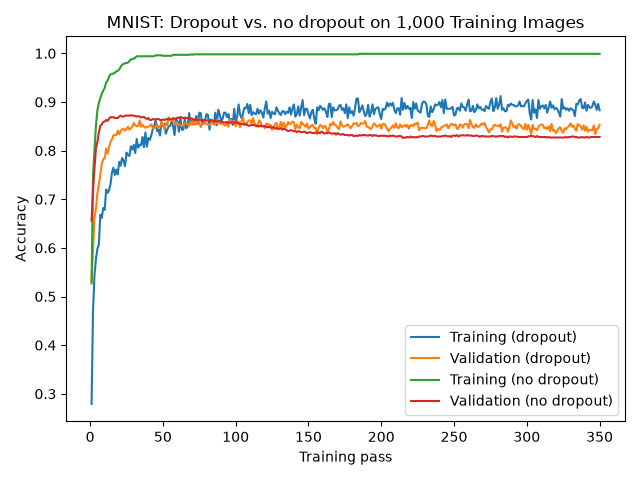

## Part 4 - Train of Formation

In [4]:
import time
import numpy as np
from data import load_mnist, one_hot
from part1_memorize import relu, relu_d, evaluate


def train_batched(X_train, Y_train, X_val, Y_val, iterations=350, batch_size=100):
    """
    Trains a 784 -> 40 -> 10 network using mini-batches and dropout.
    
    Parameters:
        X_train, Y_train: Training data (1000 images, one-hot labels)
        X_val, Y_val: Validation data (1000 images, one-hot labels)
        iterations: Number of epochs (passes over the training set)
        batch_size: Number of images per mini-batch step
        
    Returns:
        W_0_1, W_1_2: Updated layer weights
        train_hist: List of training accuracy (running count) per iteration
        val_hist: List of validation accuracy per iteration
    """
    # Seed FIRST, then initialize weights
    np.random.seed(1)
    
    # Batch learning rate raised from 0.005 to 0.1
    alpha = 0.1
    hidden_size = 40
    
    # Initialize weights in [-0.1, 0.1)
    W_0_1 = 0.2 * np.random.random((784, hidden_size)) - 0.1
    W_1_2 = 0.2 * np.random.random((hidden_size, 10)) - 0.1
    
    train_hist = []
    val_hist = []
    
    num_samples = X_train.shape[0]
    
    for epoch in range(iterations):
        correct_cnt = 0
        
        # Mini-batch inner loop
        for i in range(0, num_samples, batch_size):
            # Extract batch slices: shapes (100, 784) and (100, 10)
            batch_x = X_train[i : i + batch_size]
            batch_y = Y_train[i : i + batch_size]
            
            # Forward pass
            layer_0 = batch_x  # (100, 784)
            layer_1 = relu(np.dot(layer_0, W_0_1))  # (100, 40)
            
            # Apply Inverted Dropout (50% keep probability)
            mask = np.random.randint(2, size=layer_1.shape)  # (100, 40)
            layer_1 = layer_1 * mask * 2
            
            layer_2 = np.dot(layer_1, W_1_2)  # (100, 10)
            
            # Track running training accuracy (evaluated with dropout mask on)
            correct_cnt += np.sum(
                np.argmax(layer_2, axis=1) == np.argmax(batch_y, axis=1)
            )
            
            # Backward pass
            delta_2 = layer_2 - batch_y  # (100, 10)
            
            # Divide delta_2 by batch_size to average the gradient over the batch
            delta_2 = delta_2 / batch_size
            
            # Backpropagate through hidden layer and re-apply mask
            delta_1 = np.dot(delta_2, W_1_2.T) * relu_d(layer_1)  # (100, 40)
            delta_1 = delta_1 * mask  # Silenced units receive no gradient update
            
            # Weight updates
            W_1_2 -= alpha * np.dot(layer_1.T, delta_2)
            W_0_1 -= alpha * np.dot(layer_0.T, delta_1)
            
        # Record histories
        train_acc = correct_cnt / float(num_samples)
        val_acc = evaluate(X_val, Y_val, W_0_1, W_1_2)
        
        train_hist.append(train_acc)
        val_hist.append(val_acc)
        
    return W_0_1, W_1_2, train_hist, val_hist


if __name__ == "__main__":
    # 1. Load data and carve 1,000-image subsets
    (X_train_full, y_train_full), _ = load_mnist()
    X_val = X_train_full[1000:2000]
    Y_val = one_hot(y_train_full[1000:2000])
    X_train = X_train_full[:1000]
    Y_train = one_hot(y_train_full[:1000])
    
    # Import single-image train function from Part 3 for timing comparison
    from part3_dropout import train_dropout

    print("Running Part 3 (One-at-a-time with dropout)...")
    t0 = time.perf_counter()
    W0_p3, W1_p3, tr_p3, val_p3 = train_dropout(
        X_train, Y_train, X_val, Y_val, iterations=350, dropout=True
    )
    t_single = time.perf_counter() - t0

    print("Running Part 4 (Batched with mini-batch size=100)...")
    t0 = time.perf_counter()
    W0_p4, W1_p4, tr_p4, val_p4 = train_batched(
        X_train, Y_train, X_val, Y_val, iterations=350, batch_size=100
    )
    t_batched = time.perf_counter() - t0

    speedup = t_single / t_batched

    # Report performance and benchmark results
    print("\n--- Benchmark Results ---")
    print(f"One-at-a-time execution time : {t_single:.4f} seconds")
    print(f"Mini-batched execution time   : {t_batched:.4f} seconds")
    print(f"Speed-up factor               : {speedup:.2f}x faster")
    print("--------------------------")
    print(f"Part 3 (Single-image) Final Val Acc : {val_p3[-1]:.4f}")
    print(f"Part 4 (Batched) Final Val Acc      : {val_p4[-1]:.4f}")
    
    # Confirm validation accuracy lands within ~2 percentage points
    acc_diff = abs(val_p3[-1] - val_p4[-1])
    print(f"Absolute Validation Difference     : {acc_diff:.4f}")
    

Running Part 3 (One-at-a-time with dropout)...
Running Part 4 (Batched with mini-batch size=100)...

--- Benchmark Results ---
One-at-a-time execution time : 28.4223 seconds
Mini-batched execution time   : 2.1514 seconds
Speed-up factor               : 13.21x faster
--------------------------
Part 3 (Single-image) Final Val Acc : 0.8530
Part 4 (Batched) Final Val Acc      : 0.8420
Absolute Validation Difference     : 0.0110
